# Task 1 · Iris Flower Classification

Train a classifier that identifies an iris as **setosa**, **versicolor**, or **virginica** from four measurements: sepal length, sepal width, petal length, and petal width.

The data comes from `sklearn.datasets.load_iris()` (150 flowers, 50 of each species). No external download is required.


## 1. Setup


In [1]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)
SPECIES_ORDER = ["setosa", "versicolor", "virginica"]


## 2. Load the dataset

`load_iris(as_frame=True)` returns the four measurements and an integer target. The integer is mapped to the species name so later tables and plots stay readable.


In [2]:
iris = load_iris(as_frame=True)
df = iris.frame.copy()
df["species"] = df["target"].map(dict(enumerate(iris.target_names)))
df = df.drop(columns=["target"])
df.head()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 3. Exploratory data analysis

Check the table size, column types, missing values, species balance, and the usual descriptive statistics before modelling.


In [3]:
print("Shape:", df.shape)
print()
print("Data types:")
print(df.dtypes)
print()
print("Missing values:")
print(df.isnull().sum())
print()
print("Species counts:")
print(df["species"].value_counts())


Shape: (150, 5)

Data types:
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
species                  str
dtype: object

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Species counts:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [4]:
df.describe()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000,150.000,150.000,150.000
mean,5.843,3.057,3.758,1.199
std,0.828,0.436,1.765,0.762
min,4.300,2.000,1.000,0.100
25%,5.100,2.800,1.600,0.300
50%,5.800,3.000,4.350,1.300
75%,6.400,3.300,5.100,1.800
max,7.900,4.400,6.900,2.500


The table has **150 rows and 5 columns**. All four measurements are floats, the species column is text, and there are **no missing values**. Each species appears exactly 50 times, so the classes are balanced. Sepal length sits roughly between 4.3 cm and 7.9 cm. Petal width has the widest relative spread, from 0.1 cm to 2.5 cm, which is a first hint that the petal measurements vary more across flowers than the sepal ones.


## 4. Pairplot

Each panel compares two measurements. Points are coloured by species. The diagonal shows how each measurement is distributed inside a species.


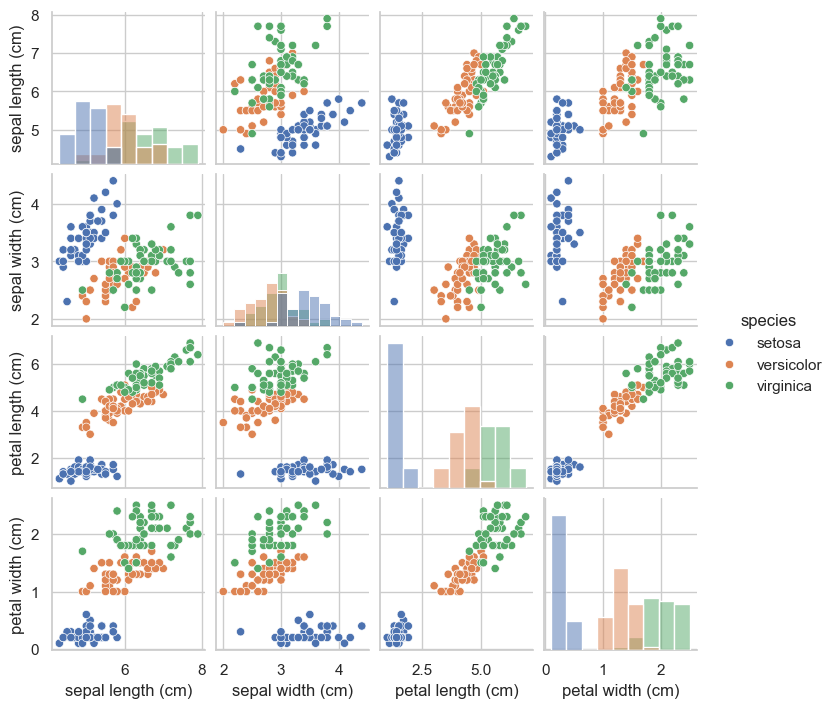

In [5]:
sns.pairplot(df, hue="species", hue_order=SPECIES_ORDER, diag_kind="hist", height=1.8)
plt.show()


Setosa separates cleanly on every panel that uses petal length or petal width. Versicolor and virginica sit closer together, with a thin overlap on both petal measurements. Sepal width is the panel where the three clouds overlap most.


## 5. Box plots

One box plot per measurement shows the median, the middle 50 percent, and the whiskers for each species.


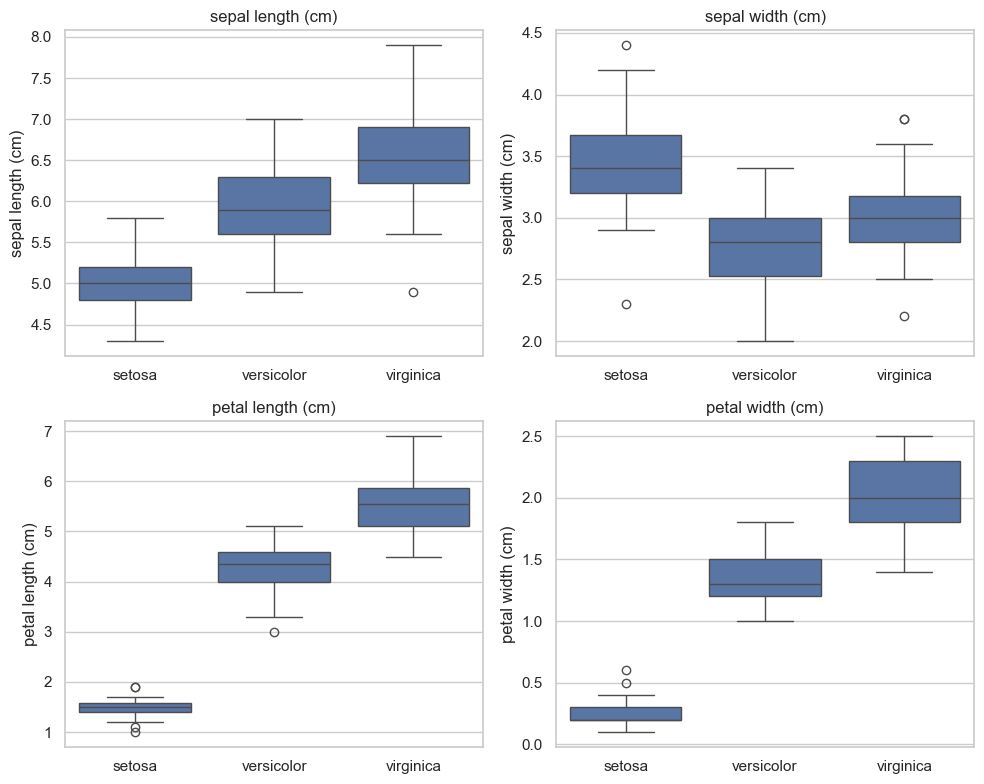

In [6]:
features = ["sepal length (cm)", "sepal width (cm)", "petal length (cm)", "petal width (cm)"]
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, feature in zip(axes.ravel(), features):
    sns.boxplot(data=df, x="species", y=feature, order=SPECIES_ORDER, ax=ax)
    ax.set_title(feature)
    ax.set_xlabel("")
fig.tight_layout()
plt.show()


Petal length and petal width have almost no overlap between setosa and the other two species, and only a small overlap between versicolor and virginica. Sepal length increases from setosa to virginica, but the boxes overlap. Sepal width runs the other way: setosa tends to be wider, and versicolor and virginica occupy nearly the same range.


## 6. Which features are most discriminative?

The class means make the same pattern numeric. A feature is discriminative when the three species sit far apart on it and their ranges do not pile up.


In [7]:
class_means = df.groupby("species")[features].mean().loc[SPECIES_ORDER]
class_means


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
species,,,,
setosa,5.006,3.428,1.462,0.246
versicolor,5.936,2.770,4.260,1.326
virginica,6.588,2.974,5.552,2.026


**Petal length and petal width are the features to keep.** Setosa petals are short and narrow, versicolor sits in the middle, and virginica has the longest and widest petals. Those two measurements also move together, so either one already separates setosa, and together they do most of the work of separating versicolor from virginica.

**Sepal length** helps, but only as a weak extra signal: the species shift in the same direction, with much more overlap.

**Sepal width is the least useful feature.** The species ranges sit on top of each other, and setosa is wider rather than narrower, so the direction does not match the other three measurements. A model can still use it, but petal length and petal width carry the classification.


## 7. Train/test split

The split is 80/20 and stratified, so each species keeps the same share in the training set and the test set (40 train and 10 test per species). `random_state=42` makes the split repeatable.


In [8]:
X = df[features]
y = df["species"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Training rows:", X_train.shape[0])
print("Test rows:", X_test.shape[0])
print()
print(y_test.value_counts().loc[SPECIES_ORDER])


Training rows: 120
Test rows: 30

species
setosa        10
versicolor    10
virginica     10
Name: count, dtype: int64


## 8. Train four classifiers

Logistic regression and k-nearest neighbours use a scaled copy of the features, because both compare measurements by distance or by a shared coefficient scale. The tree models split on one measurement at a time, so they keep the original centimetres.

- Logistic regression
- K-nearest neighbours (`k = 5`)
- Decision tree
- Random forest (200 trees)


In [9]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, random_state=42)),
    ]),
    "K-Nearest Neighbours": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5)),
    ]),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
predictions = {}
score_rows = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predicted = model.predict(X_test)
    predictions[name] = predicted
    cv_scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
    score_rows.append({
        "model": name,
        "test_accuracy": accuracy_score(y_test, predicted),
        "cv_mean_accuracy": cv_scores.mean(),
        "cv_std_accuracy": cv_scores.std(),
    })


## 9. Evaluation

For each model: accuracy on the held-out 30 flowers, a confusion matrix, and the precision / recall / F1 report. A five-fold stratified cross-validation score is included so a tie on 30 test rows is not the only evidence.


In [10]:
comparison = pd.DataFrame(score_rows).set_index("model")
comparison = comparison.sort_values(
    ["cv_mean_accuracy", "test_accuracy"], ascending=False
)
comparison


,test_accuracy,cv_mean_accuracy,cv_std_accuracy
model,,,
K-Nearest Neighbours,0.933,0.973,0.025
Random Forest,0.900,0.960,0.039
Decision Tree,0.933,0.953,0.034
Logistic Regression,0.933,0.953,0.045


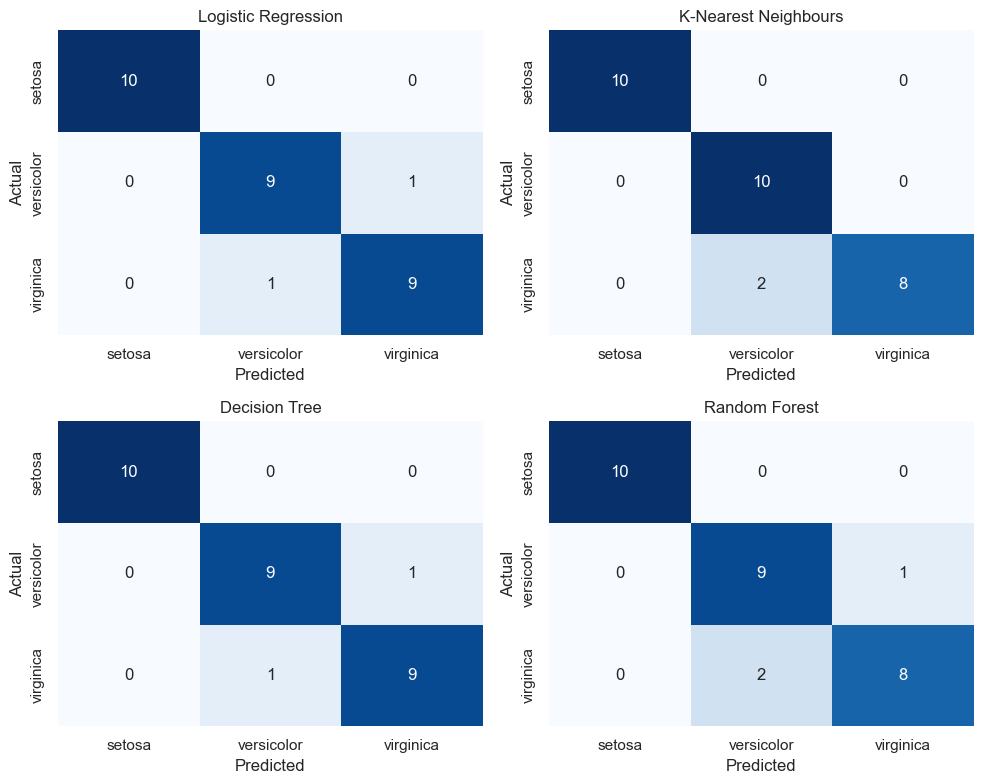

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, name in zip(axes.ravel(), models):
    matrix = confusion_matrix(y_test, predictions[name], labels=SPECIES_ORDER)
    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=SPECIES_ORDER,
        yticklabels=SPECIES_ORDER,
        ax=ax,
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
fig.tight_layout()
plt.show()


In [12]:
for name in models:
    print("=" * 60)
    print(name)
    print("Accuracy:", round(accuracy_score(y_test, predictions[name]), 3))
    print()
    print(classification_report(y_test, predictions[name], labels=SPECIES_ORDER, digits=3))


Logistic Regression
Accuracy: 0.933

              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.900     0.900     0.900        10
   virginica      0.900     0.900     0.900        10

    accuracy                          0.933        30
   macro avg      0.933     0.933     0.933        30
weighted avg      0.933     0.933     0.933        30

K-Nearest Neighbours
Accuracy: 0.933

              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.833     1.000     0.909        10
   virginica      1.000     0.800     0.889        10

    accuracy                          0.933        30
   macro avg      0.944     0.933     0.933        30
weighted avg      0.944     0.933     0.933        30

Decision Tree
Accuracy: 0.933

              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.900

## 10. Best model

**K-nearest neighbours is the best model on this split.**

| Model | Test accuracy | 5-fold CV accuracy |
| --- | ---: | ---: |
| K-nearest neighbours | 0.933 | 0.973 |
| Random forest | 0.900 | 0.960 |
| Logistic regression | 0.933 | 0.953 |
| Decision tree | 0.933 | 0.953 |

Three models tie on the 30-row test set at 93.3% accuracy. K-nearest neighbours is preferred for three reasons:

1. Its cross-validated accuracy is the highest, at 97.3%, and it also has the smallest fold-to-fold spread.
2. On the test report its macro precision is 0.944, ahead of logistic regression and the decision tree at 0.933. Macro F1 is tied at 0.933.
3. Every model classifies setosa perfectly. The remaining mistakes are virginica flowers called versicolor, which matches the overlap visible in the petal plots. K-nearest neighbours makes two of those mistakes and no mistakes in the other direction.

Logistic regression is a close second and is easier to explain coefficient by coefficient. For raw accuracy and stability on this dataset, k-nearest neighbours is the one to keep.
